# 04 · Protocolo P1: inclinações aleatórias e comparação fora da amostra

O protocolo pré-registrado P1 mede o erro de previsão de log(unidades), condicionada ao preço e à promoção observados na semana. Os scripts ajustaram os modelos e fizeram a avaliação final uma vez cada. As duas versões deste notebook leem as mesmas três execuções em `outputs/runs` (`p1_folds`, `gpboost_tuning` e `p1_final`). A seção 9 consulta uma quarta execução, com o teste inferencial complementar feito somente no treino após a conclusão do P1.

*Dados: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "pt"

In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from retail_multilevel import interpret, viz
from retail_multilevel.i18n import t
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
folds = load_run("p1_folds", "20261124-135426-7e46f16b")
tuning = load_run("gpboost_tuning", "20261124-135420-206b7827")
final = load_run("p1_final", "20261124-144615-0aba3b28")
print(t("data_credit", LANG))
stored = {r.metadata["experiment"]: r for r in (folds, tuning, final)}
display(
    pd.DataFrame(
        {name: {"run_id": r.run_id, "finished_at": r.metadata["finished_at"]} for name, r in stored.items()}
    ).T
)

Dados: dunnhumby Source Files – Breakfast at the Frat


,run_id,finished_at
p1_folds,20261124-135426-7e46f16b,2026-11-24T13:58:23.622228
gpboost_tuning,20261124-135420-206b7827,2026-11-24T14:39:36.425349
p1_final,20261124-144615-0aba3b28,2026-11-24T14:47:28.624803


As três execuções lidas estão identificadas acima (identificador e horário de término). Os identificadores são fixados no código, de modo que reexecutar o notebook lê sempre os mesmos artefatos.

## 1. A pergunta e o pré-registro

O notebook 03 estimou uma elasticidade ao desconto comum a todos os pares loja × produto. O P1 avalia se permitir que essa elasticidade varie entre lojas e produtos melhora a previsão fora da amostra, sobretudo para pares com pouco histórico. Para isso, testa inclinações aleatórias de `LOG_DISC` (Gelman & Hill, 2007). Quando há poucas semanas no histórico, a elasticidade ajustada só com os dados do par pode ser instável. O encolhimento em direção às médias da loja e do produto pode estabilizar a estimativa (Robinson, 1991).

O protocolo e suas seis emendas (E1 a E6) foram aprovados antes do ajuste de qualquer candidato, conforme a prática de pré-registro (Nosek et al., 2018; Weston et al., 2019). O registro fixou os candidatos, a ordem de comparação, a regra de parada, a métrica e as populações. As emendas definiram o F3 do notebook 03 como candidato inicial C0 (E1), a cobertura do OLS por par (E2), a regra sequencial de parada (E3) e o congelamento antes da avaliação final (E6). Os limiares e as fórmulas já estavam definidos quando saíram os resultados das dobras internas.

Todos os candidatos compartilham a parte fixa do F3 (decisões D12 a D14) e as mesmas linhas.

| Candidato | Especificação além da parte fixa do F3 | Situação neste notebook |
|---|---|---|
| C0 | Interceptos aleatórios de loja, de produto e do par, com uma elasticidade ao desconto comum | Ajustado nas dobras e na janela final |
| C1 | C0 mais inclinações aleatórias independentes de `LOG_DISC` por produto e por loja | Ajustado nas dobras e rejeitado |
| C2 | C1 com intercepto e inclinação correlacionados, por produto e por loja | Não ajustado (a sequência parou) |
| C3 | O melhor entre C1 e C2, mais inclinação aleatória de `LOG_DISC` por par | Não ajustado (a sequência parou) |
| C4 | O melhor anterior, mais inclinações aleatórias de `FEATURE` e `DISPLAY` por produto | Não ajustado (a sequência parou) |

A sequência compara C1, C2, C3 e C4, nessa ordem, sempre com o último modelo aceito. Para ser aceito, o candidato precisa convergir sem singularidade (Bates et al., 2015), com nova tentativa pelo otimizador `nloptwrap` em caso de aviso. O MAE por par deve ser menor nas duas dobras internas, com redução relativa de pelo menos 0,5% na média das dobras. Se alguma condição falhar, a sequência termina e mantém o último modelo aceito.

A seleção usa duas dobras internas (Tashman, 2000) dentro das 104 semanas de treino. Na dobra A, o ajuste usa as semanas 0 a 51 e a validação usa as semanas 52 a 77. Na dobra B, o ajuste usa as semanas 0 a 77 e a validação usa as semanas 78 a 103. Todas as transformações aprendidas, como as médias de par, são recalculadas dentro de cada janela de ajuste. Só depois da seleção o modelo escolhido é reajustado nas semanas 0 a 103 e pontuado nas semanas 104 a 155.

## 2. Métrica, populações, referências e congelamento

A métrica principal é o erro absoluto médio (MAE) de `LOG_UNITS`, calculado primeiro dentro de cada par e depois promediado com peso igual por par. Cada par conta, portanto, uma vez, independentemente do número de semanas, e o MAE por linha (peso igual por linha) é relatado como medida complementar. As previsões são condicionais ao preço e à promoção realizados na semana, e a população são as linhas do modelo, uma coorte retrospectiva, porque o filtro das linhas usa informação conhecida só depois da venda.

Três populações são comparadas, e os pares são divididos em estratos de histórico, contados na janela de ajuste (menos de 26, de 26 a 77 e 78 semanas ou mais).

| População | Definição |
|---|---|
| (a) Pares vistos | Pares presentes na janela de ajuste. É a população da comparação principal |
| (b) Linhas cobertas pelo OLS por par | Subconjunto de (a) em que o OLS por par consegue prever (emenda E2), com todos os modelos avaliados nas mesmas linhas |
| (c) Pares inéditos | Pares sem histórico na janela de ajuste, relatados à parte, com efeito de par igual a zero |

As referências são o OLS agrupado (a parte fixa do F3, sem efeitos aleatórios), o OLS por par (ajustado com `LOG_DISC`, `FEATURE`, `DISPLAY` e `TPR_ONLY`, só nos pares com pelo menos 8 semanas na janela de ajuste) e o GPBoost (Sigrist, 2022), um desafiante secundário de aprendizado de máquina com efeitos de grupo de loja, de produto e de par. Os hiperparâmetros do GPBoost foram calibrados somente nas dobras internas, e ele não participa da sequência de seleção.

Antes da avaliação final, o modelo selecionado (C0), os parâmetros do GPBoost, as versões do código e o painel foram congelados e registrados no registro de decisões, e a avaliação das semanas 104 a 155 foi prevista uma única vez, com o resultado publicado em qualquer direção. A tabela a seguir compara os hashes de congelamento (12 primeiros caracteres do SHA-256) com os calculados no momento da pontuação. Essa janela, porém, é uma janela de avaliação temporal **retrospectiva, com exposição exploratória prévia** (D11 revisada): o painel inteiro foi explorado antes do protocolo, e a formulação do modelo, como a decomposição de preço da D12, é uma decisão de desenvolvimento. Ela não é um conjunto de teste intocado nem cego.

In [3]:
cfg = final.metadata["config"]
hashes = pd.DataFrame({"frozen": cfg["frozen_hashes"], "at_scoring": cfg["current_hashes"]})
hashes["identical"] = hashes["frozen"] == hashes["at_scoring"]
display(hashes)
display(pd.Series(final.load_json("summary")).to_frame("summary"))

,frozen,at_scoring,identical
p1.py,ea3a8451b6ad,ea3a8451b6ad,True
gpb.py,1f66d53e668a,1f66d53e668a,True
features.py,cc5f2d2e5216,cc5f2d2e5216,True
fixedeffects.py,7b8725e5e6d5,7b8725e5e6d5,True
multilevel.py,bfde1e86abb6,bfde1e86abb6,True
split.py,36ab08e67f0e,36ab08e67f0e,True
cleaning.py,047e1279b041,047e1279b041,True
panel.parquet,f3066b4c7fce,f3066b4c7fce,True


,summary
c0_converged_ok,True
c0_scored,True
n_fit_rows,347092
n_val_rows,177767


## 3. Seleção nas dobras internas

A tabela mostra o registro da sequência de seleção. O C1 foi comparado com o C0, e o resultado determinou a parada da sequência.

In [4]:
folds_m = folds.load_table("metrics")
log = interpret.selection_table(folds.load_table("selection_log"), LANG)
display(log.set_index(t("col_candidate", LANG)).T)
display(folds.load_table("convergence"))
display(folds.load_table("coverage").T.rename(columns={0: "A", 1: "B"}))

Candidato,C1,C2,C3,C4
Comparado com,C0,C0,C0,C0
"MAE, dobra A",0.4294,NaN,NaN,NaN
"MAE, dobra A, modelo aceito",0.4230,NaN,NaN,NaN
"MAE, dobra B",0.4188,NaN,NaN,NaN
"MAE, dobra B, modelo aceito",0.4211,NaN,NaN,NaN
"Ganho, dobra A (%)",-1.5185,NaN,NaN,NaN
"Ganho, dobra B (%)",0.5432,NaN,NaN,NaN
Ganho médio (%),-0.4876,NaN,NaN,NaN
Decisão,rejeitado,não ajustado,não ajustado,não ajustado


,model,fold,n_messages,messages,singular,optimizer,seconds,npar,nobs
0,C0,A,0,,False,bobyqa,18.9982,18,167695
1,C0,B,0,,False,bobyqa,27.5864,18,256650
2,C1,A,0,,False,bobyqa,44.4705,20,167695
3,C1,B,0,,False,bobyqa,84.6404,20,256650


,A,B
fold,A,B
n_seen_pairs,3671,3786
n_seen_rows,87213,90362
n_seen_pairs_with_ols,3635,3757
n_covered_pairs,3631,3756
n_covered_rows,85267,88374
pct_pairs_covered,98.9104,99.2076
pct_rows_covered,97.7687,97.8000
n_unseen_pairs,4,13
n_unseen_rows,32,80


Os quatro ajustes (C0 e C1 em cada dobra) convergiram com o otimizador bobyqa, sem mensagens e sem singularidade, em 19 a 85 s, com 18 parâmetros no C0 e 20 no C1. O C1 teve MAE por par de 0,4294 na dobra A, contra 0,4230 do C0, um ganho de −1,52%, isto é, uma piora. Na dobra B, o MAE foi de 0,4188 contra 0,4211, um ganho de 0,54%. O ganho médio, de −0,49%, ficou abaixo do limiar de 0,5%, e a regra rejeitou o C1. O C2, o C3 e o C4 não foram ajustados.

A cobertura das dobras mostra que o OLS por par cobriu 98,9% dos pares e 97,8% das linhas na dobra A, e 99,2% e 97,8% na dobra B. Os pares inéditos são só 4 na dobra A (32 linhas) e 13 na dobra B (80 linhas), pequenos demais para qualquer conclusão, e na dobra A, 1.710 linhas de validação não têm UPC na janela de ajuste e entram só na contagem de cobertura.

,Dobra,Estrato de histórico,Pares,Linhas,C0,C1,OLS agrupado
0,A,Todos,3671,87213,0.4230,0.4294,0.9149
1,A,< 26 semanas,246,3227,0.3828,0.3686,1.1575
2,A,26-77 semanas,3425,83986,0.4259,0.4338,0.8975
3,B,Todos,3786,90362,0.4211,0.4188,0.9036
4,B,< 26 semanas,221,3598,0.4999,0.4956,1.0150
5,B,26-77 semanas,1951,44901,0.4676,0.4669,0.9781
6,B,≥ 78 semanas,1614,41863,0.3542,0.3503,0.7983


(b) Linhas cobertas pelo OLS por par


,Dobra,Estrato de histórico,Pares,Linhas,C0,C1,OLS por par,OLS agrupado
0,A,Todos,3631,85267,0.4230,0.4305,0.4690,0.9117
1,A,< 26 semanas,208,2735,0.3719,0.3647,0.4346,1.1445
2,A,26-77 semanas,3423,82532,0.4261,0.4345,0.4711,0.8975
3,B,Todos,3756,88374,0.4190,0.4170,0.4549,0.8987
4,B,< 26 semanas,192,3055,0.4856,0.4904,0.5084,0.9629
5,B,26-77 semanas,1950,44268,0.4671,0.4666,0.5185,0.9768
6,B,≥ 78 semanas,1614,41051,0.3530,0.3483,0.3716,0.7968


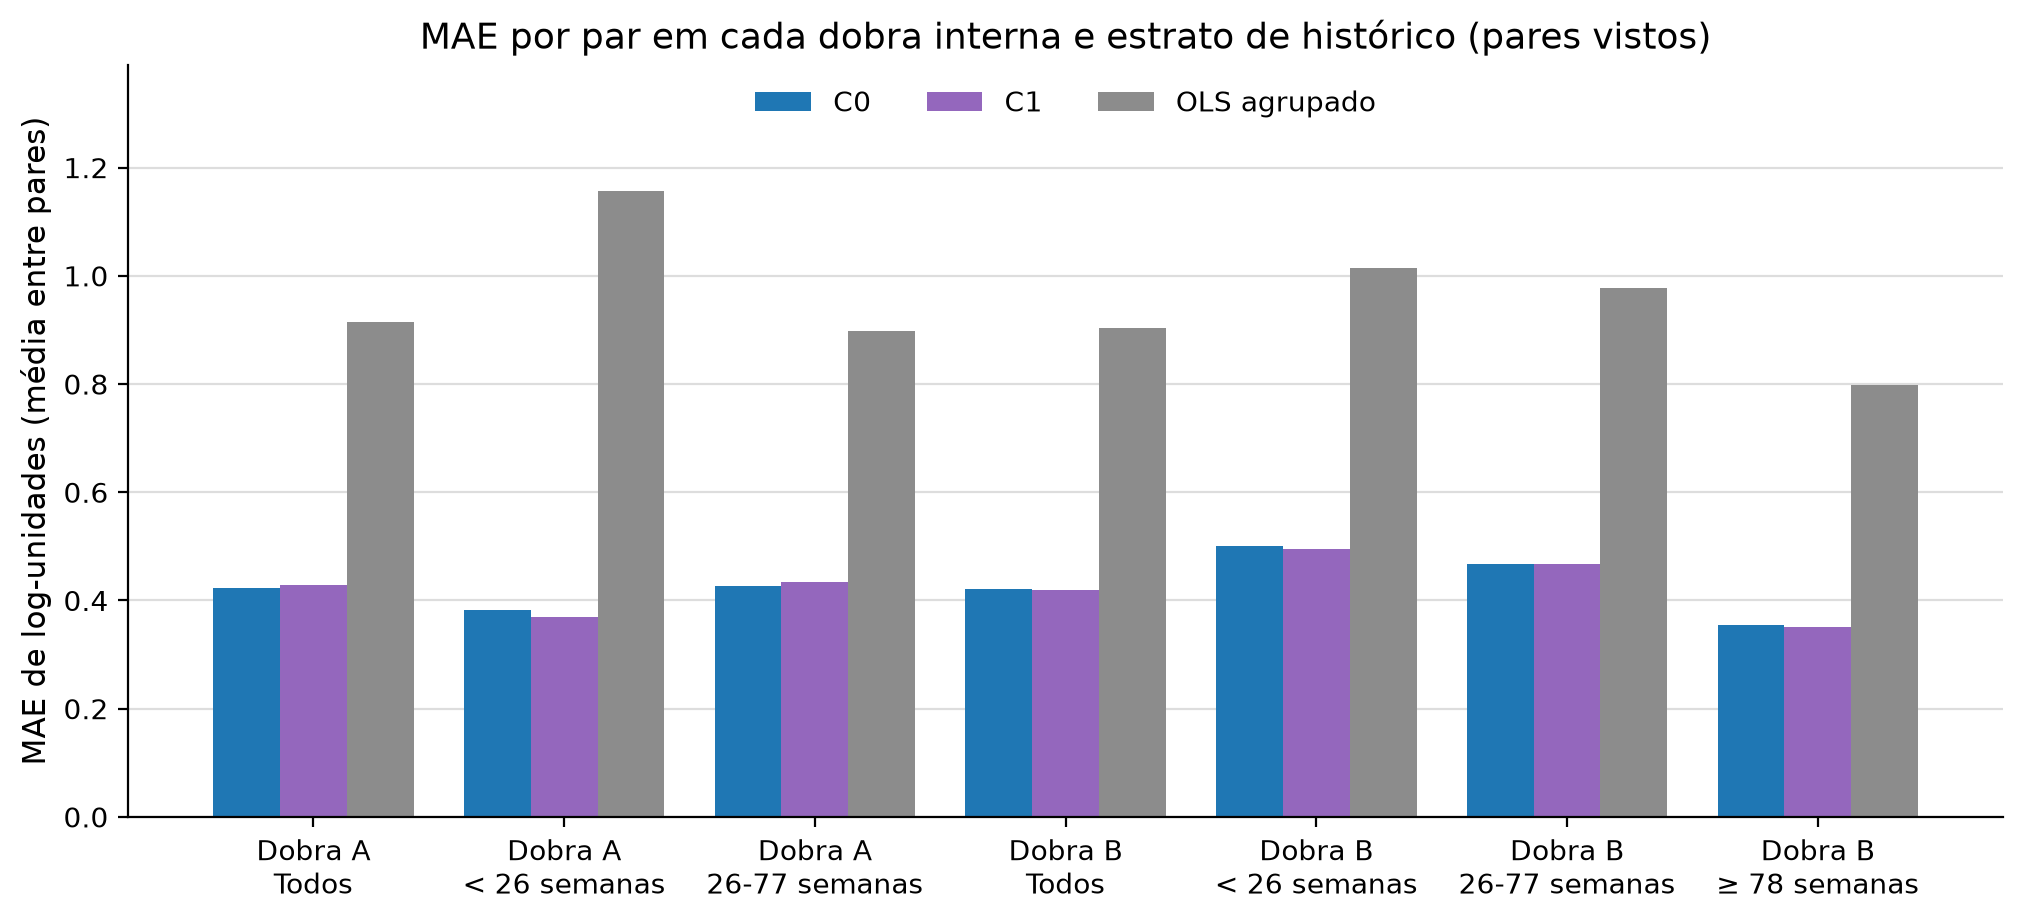

In [5]:
fig = viz.plot_fold_mae(folds_m, LANG)
display(interpret.metric_table(folds_m, "a_seen", LANG, models=["C0", "C1", "OLS_pooled"]))
print(t("pop_b_ols_covered", LANG))
display(interpret.metric_table(folds_m, "b_ols_covered", LANG, models=["C0", "C1", "OLS_pair", "OLS_pooled"]))

O gráfico e a primeira tabela mostram o MAE por par nos pares vistos, por dobra e por estrato de histórico. O OLS agrupado teve MAE de 0,9149 na dobra A e de 0,9036 na dobra B, mais que o dobro do C0. O C1 foi melhor que o C0 no estrato com menos de 26 semanas nas duas dobras (dobra A: 0,3686 contra 0,3828; dobra B: 0,4956 contra 0,4999), na direção da hipótese. Ele foi pior no estrato de 26 a 77 semanas da dobra A (0,4338 contra 0,4259), que concentra 3.425 dos 3.671 pares dessa dobra. O estrato de 78 semanas ou mais está vazio na dobra A por construção, porque a janela de ajuste tem só 52 semanas. Na população (b), o C0 teve MAE por par menor que o do OLS por par nas duas dobras (0,4230 contra 0,4690 na dobra A, e 0,4190 contra 0,4549 na dobra B).

In [6]:
weekly_folds = folds.load_table("weekly_diff")
display(interpret.weekly_summary_table(weekly_folds, LANG))
display(weekly_folds.loc[weekly_folds.groupby("fold")["mae_diff"].idxmin(), ["fold", "WEEK", "mae_diff"]])

,Dobra,Candidato,Referência,Semanas,Semanas em que o candidato é melhor,Diferença média,Diferença mínima,Diferença máxima
0,A,C1,C0,26,5,0.0082,-0.0548,0.0278
1,B,C1,C0,26,19,-0.0022,-0.0163,0.0180


,fold,WEEK,mae_diff
9,A,61,-0.0548
35,B,87,-0.0163


A série semanal da diferença entre o C1 e o C0 (negativa quando o C1 é melhor) reforça a inconsistência entre as dobras. Na dobra A, o C1 foi melhor em 5 das 26 semanas, com diferença média de +0,0082, isto é, pior. Na dobra B, foi melhor em 19 das 26 semanas, com média de −0,0022. O maior ganho do C1 na dobra A, de −0,0548, ocorreu na semana 61, a do choque comum de semana investigado no notebook 03. Um ganho que muda de sinal entre as dobras é o caso em que a regra mantém o modelo mais simples.

## 4. Calibração do GPBoost

O GPBoost foi calibrado com Optuna (Akiba et al., 2019) e amostrador TPE (Bergstra et al., 2011) em 50 tentativas, e o objetivo foi a média, nas duas dobras, do MAE por par dos pares vistos. Por tempo de execução, cada tentativa usou uma subamostra fixa de 50% dos pares da janela de ajuste e no máximo 300 rodadas, sem parada antecipada; os dois limites constam da configuração gravada da execução (`fit_frac` e `max_rounds`). A coluna de rodadas da tabela registra o valor amostrado pela busca, antes do limite.

In [7]:
best = tuning.load_json("best_params")
trials = tuning.load_table("trials")
space = trials.filter(like="params_").agg(["min", "max"]).T
space.index = space.index.str.removeprefix("params_")
space["selected"] = pd.Series({**best["params"], "num_boost_round": best["num_boost_round"]})
display(space)
print("trials:", len(trials), "| complete:", int((trials["state"] == "COMPLETE").sum()))
print("objective of the selected trial:", round(best["objective"], 4))
display(interpret.gpboost_fold_table(folds_m, tuning.load_table("fold_metrics"), LANG))

,min,max,selected
feature_fraction,0.6007,0.9950,0.6012
lambda_l2,0.0011,5.3865,0.0115
learning_rate,0.0102,0.2116,0.0196
min_data_in_leaf,63.0000,483.0000,459.0000
num_boost_round,55.0000,896.0000,60.0000
num_leaves,8.0000,126.0000,104.0000


trials: 50 | complete: 50
objective of the selected trial: 0.4651


,Dobra,"C0, MAE por par","GPBoost, MAE por par",GPBoost vs. C0 (%)
0,A,0.4230,0.4148,-1.9451
1,B,0.4211,0.4133,-1.8637


Os parâmetros selecionados ficaram perto das bordas do espaço de busca: 60 rodadas (o menor valor amostrado foi 55, e o espaço começa em 50), `min_data_in_leaf` de 459 (o maior valor amostrado foi 483, e o espaço termina em 500) e `feature_fraction` de 0,601 (o menor valor amostrado foi 0,6007, e o espaço começa em 0,6). A parte de árvores fica, portanto, pouco ajustada. Isso é uma limitação, e o espaço não foi reaberto, porque essa seria uma decisão tomada depois de ver o resultado.

Reajustado na janela inteira de cada dobra, o GPBoost teve MAE por par de 0,4148 na dobra A e de 0,4133 na dobra B, contra 0,4230 e 0,4211 do C0, diferenças de −1,95% e −1,86%. Essa comparação favorece o GPBoost, porque os hiperparâmetros dele foram escolhidos nessas mesmas dobras e o C0 não tem hiperparâmetros. Os valores das dobras não são, portanto, uma comparação justa entre os dois modelos.

## 5. A janela final (semanas 104 a 155)

O C0 foi reajustado nas semanas 0 a 103 (347.092 linhas) e pontuou 177.767 linhas das semanas 104 a 155, a janela retrospectiva com exposição exploratória prévia. O ajuste convergiu com bobyqa, sem mensagens e sem singularidade, em cerca de 32 s e com 18 parâmetros. As tabelas a seguir apresentam a convergência, a cobertura do OLS por par e o MAE por par e por linha em cada população.

In [8]:
final_m = final.load_table("metrics")
display(final.load_table("convergence"))
display(final.load_table("coverage").T.rename(columns={0: "final"}))
for pop in ("a_seen", "b_ols_covered", "c_unseen"):
    print(t("pop_" + pop, LANG), "|", t("metric_mae_pair", LANG))
    display(interpret.metric_table(final_m, pop, LANG))

,model,fold,n_messages,messages,singular,optimizer,seconds,npar,nobs
0,C0,final,0,,False,bobyqa,32.4328,18,347092


,final
fold,final
n_seen_pairs,3820
n_seen_rows,176529
n_seen_pairs_with_ols,3795
n_covered_pairs,3779
n_covered_rows,174206
pct_pairs_covered,98.9267
pct_rows_covered,98.6841
n_unseen_pairs,50
n_unseen_rows,1238


(a) Pares vistos | MAE por par


,Estrato de histórico,Pares,Linhas,C0,GPBoost,OLS agrupado
0,Todos,3820,176529,0.4541,0.4520,0.9172
1,< 26 semanas,98,1489,0.5430,0.4376,1.3143
2,26-77 semanas,546,20075,0.4922,0.4791,1.1412
3,≥ 78 semanas,3176,154965,0.4448,0.4478,0.8664


(b) Linhas cobertas pelo OLS por par | MAE por par


,Estrato de histórico,Pares,Linhas,C0,GPBoost,OLS por par,OLS agrupado
0,Todos,3779,174206,0.4510,0.4506,0.4941,0.9131
1,< 26 semanas,59,1008,0.4773,0.4002,0.4063,1.3420
2,26-77 semanas,544,19040,0.4841,0.4714,0.6127,1.1385
3,≥ 78 semanas,3176,154158,0.4448,0.4479,0.4755,0.8665


(c) Pares inéditos | MAE por par


,Estrato de histórico,Pares,Linhas,C0,GPBoost,OLS agrupado
0,Todos,50,1238,0.6260,0.6876,0.9925


In [9]:
for pop in ("a_seen", "b_ols_covered", "c_unseen"):
    print(t("pop_" + pop, LANG), "|", t("metric_mae_row", LANG))
    display(interpret.metric_table(final_m, pop, LANG, value="mae_row"))

(a) Pares vistos | MAE por linha


,Estrato de histórico,Pares,Linhas,C0,GPBoost,OLS agrupado
0,Todos,3820,176529,0.4446,0.4478,0.8823
1,< 26 semanas,98,1489,0.5232,0.5199,1.1854
2,26-77 semanas,546,20075,0.4900,0.4931,1.0335
3,≥ 78 semanas,3176,154965,0.4380,0.4413,0.8598


(b) Linhas cobertas pelo OLS por par | MAE por linha


,Estrato de histórico,Pares,Linhas,C0,GPBoost,OLS por par,OLS agrupado
0,Todos,3779,174206,0.4433,0.4464,0.4771,0.8808
1,< 26 semanas,59,1008,0.4804,0.4888,0.5255,1.1493
2,26-77 semanas,544,19040,0.4845,0.4839,0.5619,1.0351
3,≥ 78 semanas,3176,154158,0.4380,0.4414,0.4664,0.8599


(c) Pares inéditos | MAE por linha


,Estrato de histórico,Pares,Linhas,C0,GPBoost,OLS agrupado
0,Todos,50,1238,0.6406,0.6495,0.9194


Nos pares vistos (população a), o MAE por par foi de 0,4541 para o C0, 0,4520 para o GPBoost e 0,9172 para o OLS agrupado, e o MAE por linha foi de 0,4446, 0,4478 e 0,8823. Por estrato, o GPBoost teve o menor MAE por par nos pares com menos de 26 semanas (0,4376 contra 0,5430 do C0) e nos de 26 a 77 semanas (0,4791 contra 0,4922), e o C0 teve o menor nos de 78 semanas ou mais (0,4448 contra 0,4478).

O OLS por par teve cobertura em 3.779 dos 3.820 pares vistos (98,9%) e em 174.206 das 176.529 linhas (98,7%). Faltou estimativa de `LOG_DISC` em 23 pares, de `FEATURE` em 825, de `DISPLAY` em 905 e de `TPR_ONLY` em 382. Nessas linhas cobertas (população b), o MAE por par foi de 0,4510 para o C0, 0,4506 para o GPBoost, 0,4941 para o OLS por par e 0,9131 para o OLS agrupado.

Nos 50 pares inéditos (população c, 1.238 linhas, nenhuma sem covariável), o MAE por par foi de 0,6260 para o C0, 0,6876 para o GPBoost e 0,9925 para o OLS agrupado. O OLS por par não tem previsão para esses pares.

,Dobra,Candidato,Referência,Semanas,Semanas em que o candidato é melhor,Diferença média,Diferença mínima,Diferença máxima
0,Janela final,C0,OLS agrupado,52,52,-0.4372,-0.4901,-0.3245
1,Janela final,C0,OLS por par,52,52,-0.0339,-0.0755,-0.0004
2,Janela final,C0,GPBoost,52,30,-0.0032,-0.0659,0.0229


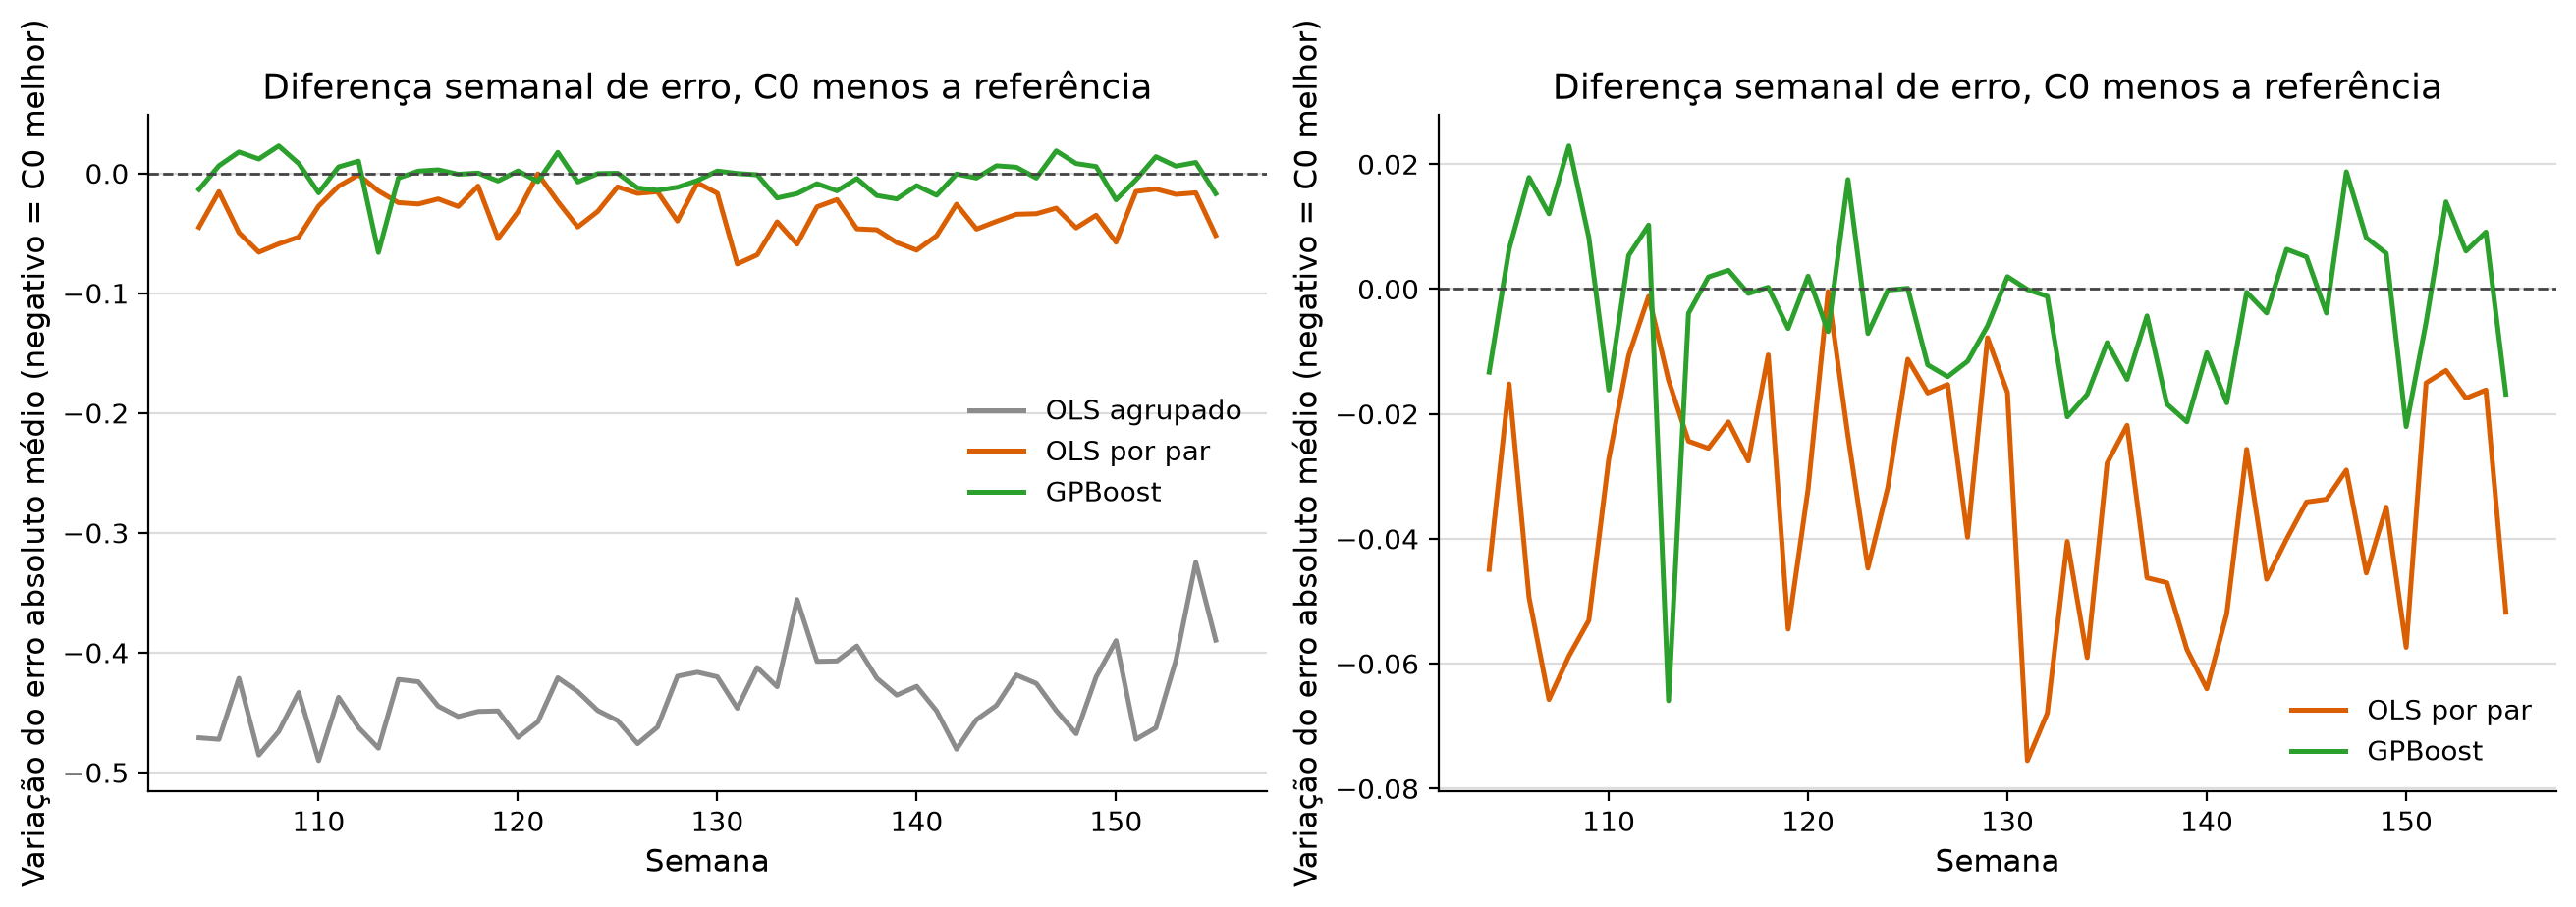

In [10]:
wd = final.load_table("weekly_diff")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
viz.plot_weekly_error_diff(wd, LANG, ax=axes[0])
viz.plot_weekly_error_diff(wd[wd["compared_to"] != "OLS_pooled"], LANG, ax=axes[1])
display(interpret.weekly_summary_table(wd, LANG))

A série semanal mostra a diferença de erro entre o C0 e cada referência, definida na execução como a média, nas linhas da semana, do erro absoluto do C0 menos o da referência (negativa quando o C0 é melhor). Ela pesa linhas, e não pares, e é descritiva. O C0 foi melhor que o OLS agrupado nas 52 semanas (diferença média de −0,4372, de −0,4901 a −0,3245) e melhor que o OLS por par nas 52 semanas (média de −0,0339, de −0,0755 a −0,0004). Contra o GPBoost, o C0 foi melhor em 30 das 52 semanas, com média de −0,0032, num intervalo de −0,0659 a +0,0229.

## 6. Primeira conclusão sobre a seleção de C0 e os pares curtos

A regra do P1 selecionou o C0 pelo desempenho nas dobras internas. O C1 reduziu o MAE por par no estrato com menos de 26 semanas nas duas dobras. Considerando todos os pares vistos, o erro aumentou na dobra A e o ganho médio de −0,49% ficou abaixo do limiar de 0,5%.

In [11]:
display(interpret.metric_table(folds_m, "a_seen", LANG, models=["C0", "C1"]))
short = {
    f: interpret.relative_difference(folds_m, "a_seen", "<26", "C1", "C0", fold=f) for f in ("A", "B")
}
label = f"{t('model_c1', LANG)} vs. {t('model_c0', LANG)}, {t('stratum_lt26', LANG)} (%)"
display(pd.Series(short, name=label).to_frame())

,Dobra,Estrato de histórico,Pares,Linhas,C0,C1
0,A,Todos,3671,87213,0.4230,0.4294
1,A,< 26 semanas,246,3227,0.3828,0.3686
2,A,26-77 semanas,3425,83986,0.4259,0.4338
3,B,Todos,3786,90362,0.4211,0.4188
4,B,< 26 semanas,221,3598,0.4999,0.4956
5,B,26-77 semanas,1951,44901,0.4676,0.4669
6,B,≥ 78 semanas,1614,41863,0.3542,0.3503


,"C1 vs. C0, < 26 semanas (%)"
A,-3.7043
B,-0.8524


No estrato com menos de 26 semanas, o MAE por par do C1 foi 3,70% menor na dobra A (246 pares) e 0,85% menor na dobra B (221 pares), em relação ao C0. São diferenças pontuais, sem análise de incerteza. Na dobra A, o estrato de 26 a 77 semanas concentra a maior parte dos pares, e ali o erro do C1 aumentou.

Pela regra do P1, a janela final avaliou apenas o candidato selecionado, o C0. Ele compartilha informação pelos interceptos e estima uma inclinação de desconto **comum** a todos os pares. A questão de saber se o ganho do C1 nos pares curtos das dobras se manteria na janela final continua em aberto.

## 7. Segunda conclusão sobre C0 e GPBoost na janela final

Nos pares vistos, o GPBoost teve MAE por par 0,47% menor que o do C0 (0,4520 contra 0,4541). O C0 teve menor MAE por linha (0,4446 contra 0,4478) e menor MAE por par nos pares inéditos (0,6260 contra 0,6876).

In [12]:
specs = [
    ("a_seen", "all", "mae_pair_mean"),
    ("a_seen", "all", "mae_row"),
    ("c_unseen", "all", "mae_pair_mean"),
    ("c_unseen", "all", "mae_row"),
]
display(interpret.model_comparison(final_m, LANG, specs, ["C0", "GPBoost"], rel=("GPBoost", "C0")))
display(interpret.metric_table(final_m, "a_seen", LANG, models=["C0", "GPBoost"]))

,"População, estrato e métrica",C0,GPBoost,Diferença (%)
0,(a) Pares vistos · Todos · MAE por par,0.4541,0.4520,-0.4654
1,(a) Pares vistos · Todos · MAE por linha,0.4446,0.4478,0.7182
2,(c) Pares inéditos · Todos · MAE por par,0.6260,0.6876,9.8364
3,(c) Pares inéditos · Todos · MAE por linha,0.6406,0.6495,1.3745


,Estrato de histórico,Pares,Linhas,C0,GPBoost
0,Todos,3820,176529,0.4541,0.4520
1,< 26 semanas,98,1489,0.5430,0.4376
2,26-77 semanas,546,20075,0.4922,0.4791
3,≥ 78 semanas,3176,154965,0.4448,0.4478


A diferença é apresentada como **observada**. A coluna de diferença mostra o GPBoost 0,47% abaixo do C0 no MAE por par dos pares vistos, e 0,72% acima no MAE por linha. Nos pares inéditos, o GPBoost ficou 9,84% acima no MAE por par. A vantagem do GPBoost no MAE por par concentra-se nos estratos de histórico curto e médio, e a do C0 no estrato de 78 semanas ou mais. Na série semanal, o C0 foi melhor em 30 das 52 semanas, com diferença média de −0,0032.

Não foi feita análise de incerteza para essa comparação: o bootstrap de pares está adiado, e a série semanal é descritiva. Por isso, as diferenças não são declaradas equivalentes nem significativas. Além disso, o GPBoost foi calibrado nas dobras internas com subamostra de 50% e no máximo 300 rodadas, e com parâmetros nas bordas do espaço de busca (seção 4), e a vantagem dele nas dobras (cerca de −1,9%) foi maior que a observada na janela final (−0,47%).

## 8. Terceira conclusão: o resultado nos pares curtos depende da população e da ponderação

Nos 59 pares curtos (menos de 26 semanas) cobertos pelo OLS local, o MAE por par com peso igual foi de 0,4002 para o GPBoost, 0,4063 para o OLS local e 0,4773 para o C0. No MAE por linha, nesse mesmo subconjunto, o C0 teve erro menor que o do OLS local (0,4804 contra 0,5255), e o GPBoost teve 0,4888.

In [13]:
specs = [("b_ols_covered", "<26", "mae_pair_mean"), ("b_ols_covered", "<26", "mae_row")]
display(interpret.model_comparison(final_m, LANG, specs, ["C0", "GPBoost", "OLS_pair"]))
c0 = final_m[(final_m["model"] == "C0") & (final_m["stratum"] == "<26")].set_index("population")
display(
    pd.DataFrame(
        {
            t("pop_a_seen", LANG): c0.loc["a_seen", ["n_pairs", "n_rows"]],
            t("pop_b_ols_covered", LANG): c0.loc["b_ols_covered", ["n_pairs", "n_rows"]],
        }
    ).rename(index={"n_pairs": t("col_pairs", LANG), "n_rows": t("col_rows", LANG)})
)

,"População, estrato e métrica",C0,GPBoost,OLS por par
0,(b) Linhas cobertas pelo OLS por par · < 26 semanas · MAE por par,0.4773,0.4002,0.4063
1,(b) Linhas cobertas pelo OLS por par · < 26 semanas · MAE por linha,0.4804,0.4888,0.5255


,(a) Pares vistos,(b) Linhas cobertas pelo OLS por par
Pares,98,59
Linhas,1489,1008


A cobertura do OLS por par segue a regra operacional da emenda E2. A regra trata como não estimado um termo sem variação na janela de ajuste do par ou descartado por colinearidade. Uma linha fica sem cobertura quando tem valor diferente de zero nesse termo. Só 59 dos 98 pares curtos vistos são cobertos, de modo que o subconjunto é selecionado pela própria regra do OLS local e não é uma amostra aleatória dos pares curtos. A regra operacional não equivale a um critério de estimabilidade. Se uma promoção esteve sempre ativa no treino de um par, ou sempre acompanhou o mesmo padrão de desconto, o intercepto ou os outros termos absorvem o seu nível médio, mas o ajuste fica sem base para estimar o que acontece quando ela é desativada ou quando essa relação muda. Um critério de estimabilidade, que só cobre a linha quando o seu vetor de covariáveis está no espaço gerado pelo desenho de treino do par, mudaria a classificação de 175 das 176.529 linhas de pares vistos na janela final, em 63 pares: 130 hoje cobertas deixariam de sê-lo e 45 hoje sem cobertura passariam a ser cobertas. Todas as mudanças vêm de termos descartados por colinearidade; o caso de termo constante não altera nenhuma linha nesta janela. Os resultados gravados foram preservados com a regra operacional.

O ordenamento depende, portanto, da população e da ponderação. Com peso igual por par, o OLS local (0,4063) foi melhor que o C0 (0,4773) nos 59 pares curtos cobertos, e o GPBoost (0,4002) foi o melhor dos três. Com peso igual por linha, no mesmo subconjunto, o C0 (0,4804) foi melhor que o OLS local (0,5255). As duas ponderações respondem a perguntas diferentes, e os artefatos gravados não permitem dizer quais pares sustentam a diferença. Nas dobras internas, em contraste, o C0 teve MAE por par menor que o do OLS por par também no estrato curto das linhas cobertas (seção 3 mostra a população b); a janela final não reproduziu essa ordem nos 59 pares. Nesse subconjunto, portanto, a ideia de que o encolhimento do C0 favorece sobretudo os pares de pouco histórico não se confirmou para o C0 no MAE por par, e a conclusão não se estende aos pares curtos sem cobertura do OLS local.

## 9. Teste complementar das inclinações aleatórias no treino

O notebook 02 usou a razão de verossimilhanças para comparar as estruturas de interceptos aleatórios. Aqui foi feita outra comparação, entre C0 e C1, para a hipótese conjunta de que a variância da inclinação do desconto por loja e a variância por UPC sejam iguais a zero. Os dois modelos foram ajustados por máxima verossimilhança, com a mesma parte fixa, os mesmos interceptos aleatórios e as mesmas 347.092 linhas das semanas 0 a 103.

Sob a hipótese nula, as duas variâncias estão na fronteira (Self & Liang, 1987; Stram & Lee, 1994). O teste foi calibrado por bootstrap paramétrico sob o C0 ajustado, seguindo o procedimento de simular sob o modelo restrito para calibrar a razão de verossimilhanças em modelos mistos (Halekoh & Højsgaard, 2014; Ott, 2014). Em cada uma das 39 réplicas planejadas, foi simulada uma resposta no mesmo desenho e os dois modelos foram reajustados a essa resposta. A estatística é duas vezes a diferença de log-verossimilhança entre C1 e C0. O valor-p de Monte Carlo é o número de réplicas com estatística igual ou maior que a observada, acrescido de um, dividido pelo total de réplicas acrescido de um. Os resultados abaixo foram lidos da execução gravada, sem reexecutar os ajustes.

In [14]:
slope_test = load_run("discount_slope_lr", "20261125-112223-aa33d3e6")
display(interpret.discount_slope_lr_table(slope_test, LANG))

,Medida,Valor
0,RV observada (C0 × C1),"12974,405"
1,Maior RV simulada sob C0,"5,182"
2,Réplicas válidas / planejadas,39/39
3,RV simuladas iguais ou maiores que a observada,0
4,Valor-p Monte Carlo,"0,0250"
5,Desvio-padrão da inclinação de desconto por loja (C1),"0,274"
6,Desvio-padrão da inclinação de desconto por UPC (C1),"0,884"


A LR observada foi **12.974,40**, e a maior LR simulada foi **5,18**. Nenhuma das 39 réplicas válidas atingiu a estatística observada. O valor-p de Monte Carlo foi **0,025**, a menor resolução do desenho. Sob as hipóteses do modelo, o teste conjunto rejeita a 5% que as duas variâncias sejam zero. Isso sustenta que pelo menos uma das duas inclinações varia entre grupos. Os desvios-padrão estimados separadamente por loja e UPC descrevem o ajuste do C1, e a decisão inferencial é conjunta.

A simulação reproduz a estrutura residual assumida pelo C0. A autocorrelação entre semanas do mesmo par, diagnosticada no notebook 03, limita a interpretação do valor-p. O teste documenta o ganho de ajuste no treino. Para previsão, o P1 manteve o C0 pelo erro nas dobras temporais. As semanas 104 a 155 ficaram fora deste teste complementar.

## 10. O que permanece adiado

O bootstrap por pares para medir a incerteza da diferença de erro preditivo continua adiado. Pontuar o C1 na janela final seria uma exploração posterior e exige aprovação.

Os notebooks 05 e 06 concluíram as demais análises nas semanas de treino, preservando o C0 e o resultado da comparação preditiva. O notebook 05 testou os contrastes secundários do P1 para as interações do desconto com segmento, marca própria e categoria, com correção de Holm (Holm, 1979). Também avaliou a sensibilidade ao efeito aleatório de categoria × semana. O notebook 06 comparou cenários de preço e promoção.

## Referências

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. In *Advances in Neural Information Processing Systems 24*.

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Halekoh, U., & Højsgaard, S. (2014). A Kenward-Roger approximation and parametric bootstrap methods for tests in linear mixed models – The R package pbkrtest. *Journal of Statistical Software, 59*(9), 1–32. https://doi.org/10.18637/jss.v059.i09

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70. (verificação parcial: fonte não acessível para conferência automática)

Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606. https://doi.org/10.1073/pnas.1708274114

Ott, P. K. (2014). COVTEST: A SAS macro for hypothesis testing in linear mixed effects models via parametric bootstrap. In *SAS Global Forum 2014 Proceedings* (Paper 1558-2014). https://support.sas.com/resources/papers/proceedings14/1558-2014.pdf

Robinson, G. K. (1991). That BLUP is a good thing: The estimation of random effects. *Statistical Science, 6*(1), 15–32. https://doi.org/10.1214/ss/1177011926

Self, S. G., & Liang, K.-Y. (1987). Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions. *Journal of the American Statistical Association, 82*(398), 605–610. https://doi.org/10.1080/01621459.1987.10478472

Sigrist, F. (2022). Gaussian process boosting. *Journal of Machine Learning Research, 23*, 1–46.

Stram, D. O., & Lee, J. W. (1994). Variance components testing in the longitudinal mixed effects model. *Biometrics, 50*(4), 1171–1177. https://doi.org/10.2307/2533455

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Weston, S. J., Ritchie, S. J., Rohrer, J. M., & Przybylski, A. K. (2019). Recommendations for increasing the transparency of analysis of preexisting data sets. *Advances in Methods and Practices in Psychological Science, 2*(3), 214–227. https://doi.org/10.1177/2515245919848684